# Traditional Materials Informatics – Photovoltaic Band Gap

Model comparison, **genetic-algorithm** descriptor selection (DEAP) and **applicability-domain** assessment (PCA, K-Means, distance), mirroring a classical QSAR/QSPR workflow. Full run: `pipeline/band_gap_ga_ad.py`.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
OUT = ROOT / "data/predictions/band_gap"
from IPython.display import Image, display
S = json.loads((OUT / 'band_gap_summary.json').read_text())
S['dataset']

{'n': 78164,
 'positive_rate': 0.06656517066680313,
 'n_train': 62531,
 'n_test': 15633,
 'n_descriptors': 142}

In [2]:
# 1. Model comparison on all descriptors
pd.DataFrame(S['model_comparison']).round(4)

,Model,ROC-AUC,F1-Score,PR-AUC,Accuracy,Training_Time
0,RF,0.9073,0.2967,0.4663,0.9403,27.1727
1,XGBoost,0.8997,0.2226,0.4194,0.9383,7.6511
2,ExtraTrees,0.8968,0.3849,0.4465,0.9395,24.2826
3,LightGBM,0.8953,0.3793,0.4008,0.8275,6.8944
4,kNN,0.8435,0.1910,0.3418,0.9355,3.7495
5,SVM,0.8135,0.0000,0.1999,0.9333,86.5686
6,LogReg,0.7986,0.2361,0.1801,0.6391,5.0137


,generation,max_fitness,avg_fitness,min_fitness,best_auc,best_n_features,avg_n_features
0,0,0.7911,0.7838,0.7745,0.8123,60,70.70
1,1,0.7942,0.7865,0.7790,0.8164,63,67.34
2,2,0.7956,0.7881,0.7793,0.8142,53,65.21
3,3,0.7989,0.7903,0.7824,0.8179,54,63.10
4,4,0.8004,0.7921,0.7845,0.8251,70,60.93
5,5,0.8013,0.7941,0.7861,0.8210,56,58.97
6,6,0.8037,0.7959,0.7863,0.8223,53,58.34
7,7,0.8037,0.7965,0.7865,0.8223,53,57.93
8,8,0.8067,0.7981,0.7893,0.8247,51,56.59
9,9,0.8089,0.8003,0.7883,0.8283,55,55.10


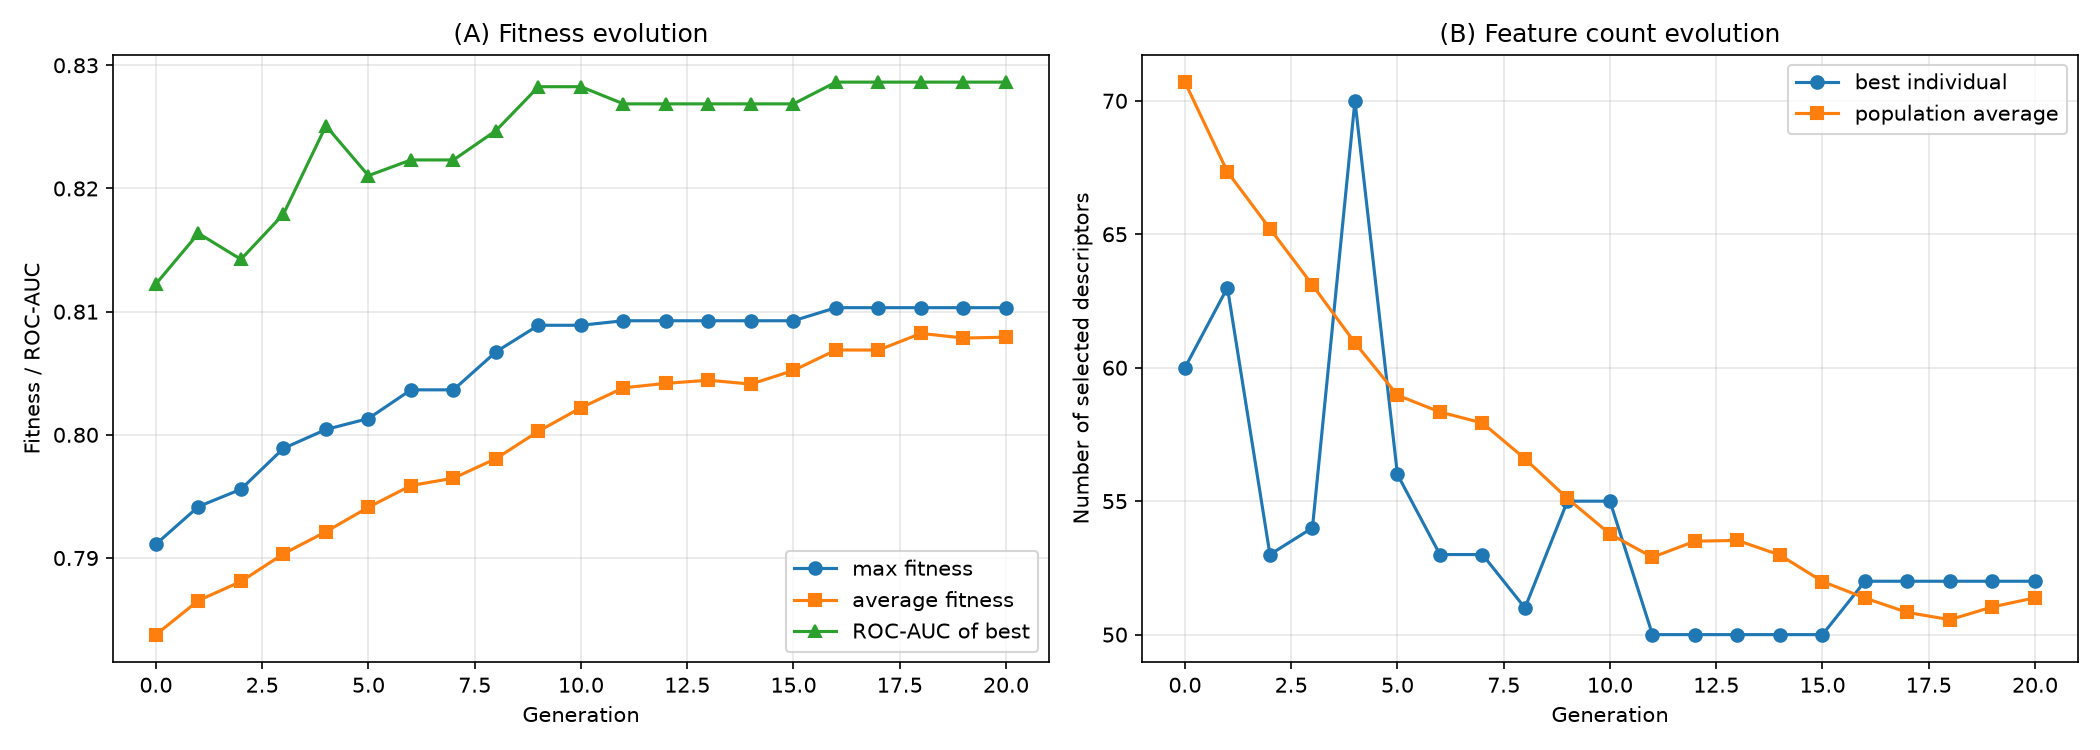

{'population': 100,
 'generations': 20,
 'cx_prob': 0.8,
 'mut_prob': 0.2,
 'elite': 5,
 'lambda': 0.05,
 'fitness_sample': 6000,
 'initial_best_auc': 0.8122502292152448,
 'final_best_auc': 0.8286315682081474,
 'initial_max_fitness': 0.7911234686518646,
 'final_max_fitness': 0.8103217090532179,
 'initial_best_n_features': 60,
 'final_n_features': 52,
 'initial_avg_n_features': 70.7,
 'final_avg_n_features': 51.38,
 'initial_min_fitness': 0.7744555148857984,
 'final_min_fitness': 0.7962279569220356,
 'all_descriptors_cv_auc': 0.8042468248822378,
 'descriptor_categories': {'electronegativity': 4,
  'radius / volume': 2,
  'valence electrons': 23,
  'periodic position': 11,
  'thermal / mass': 5,
  'elemental band gap / magnetism': 5,
  'structure (space group)': 1,
  'stoichiometry': 2}}

In [3]:
# 2. Genetic algorithm
ga = pd.read_csv(OUT / 'band_gap_ga_history.csv')
display(ga.round(4))
display(Image(str(OUT / 'band_gap_ga_evolution.png')))
{k: v for k, v in S['ga'].items() if k != 'selected_descriptors'}

In [4]:
# Selected descriptors
pd.Series(S['ga']['selected_descriptors'])

0                MagpieData minimum Number
1                MagpieData avg_dev Number
2                   MagpieData mode Number
3       MagpieData minimum MendeleevNumber
4       MagpieData maximum MendeleevNumber
5         MagpieData range MendeleevNumber
6          MagpieData minimum AtomicWeight
7            MagpieData range AtomicWeight
8              MagpieData maximum MeltingT
9                 MagpieData mean MeltingT
10                MagpieData mode MeltingT
11               MagpieData minimum Column
12                  MagpieData maximum Row
13                  MagpieData avg_dev Row
14                     MagpieData mode Row
15       MagpieData avg_dev CovalentRadius
16    MagpieData minimum Electronegativity
17    MagpieData maximum Electronegativity
18      MagpieData range Electronegativity
19       MagpieData mode Electronegativity
20              MagpieData range NsValence
21               MagpieData mean NsValence
22            MagpieData avg_dev NsValence
23         

In [5]:
# 3. Test performance: all vs GA-selected descriptors
pd.DataFrame([S['test_all_descriptors'], S['test_ga_descriptors']]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Composite_Score,n_features
0,RF-all,0.9403,0.6864,0.1892,0.2967,0.9073,0.4663,0.6020,142
1,RF-ga,0.9399,0.6678,0.1950,0.3019,0.9033,0.4552,0.6026,52


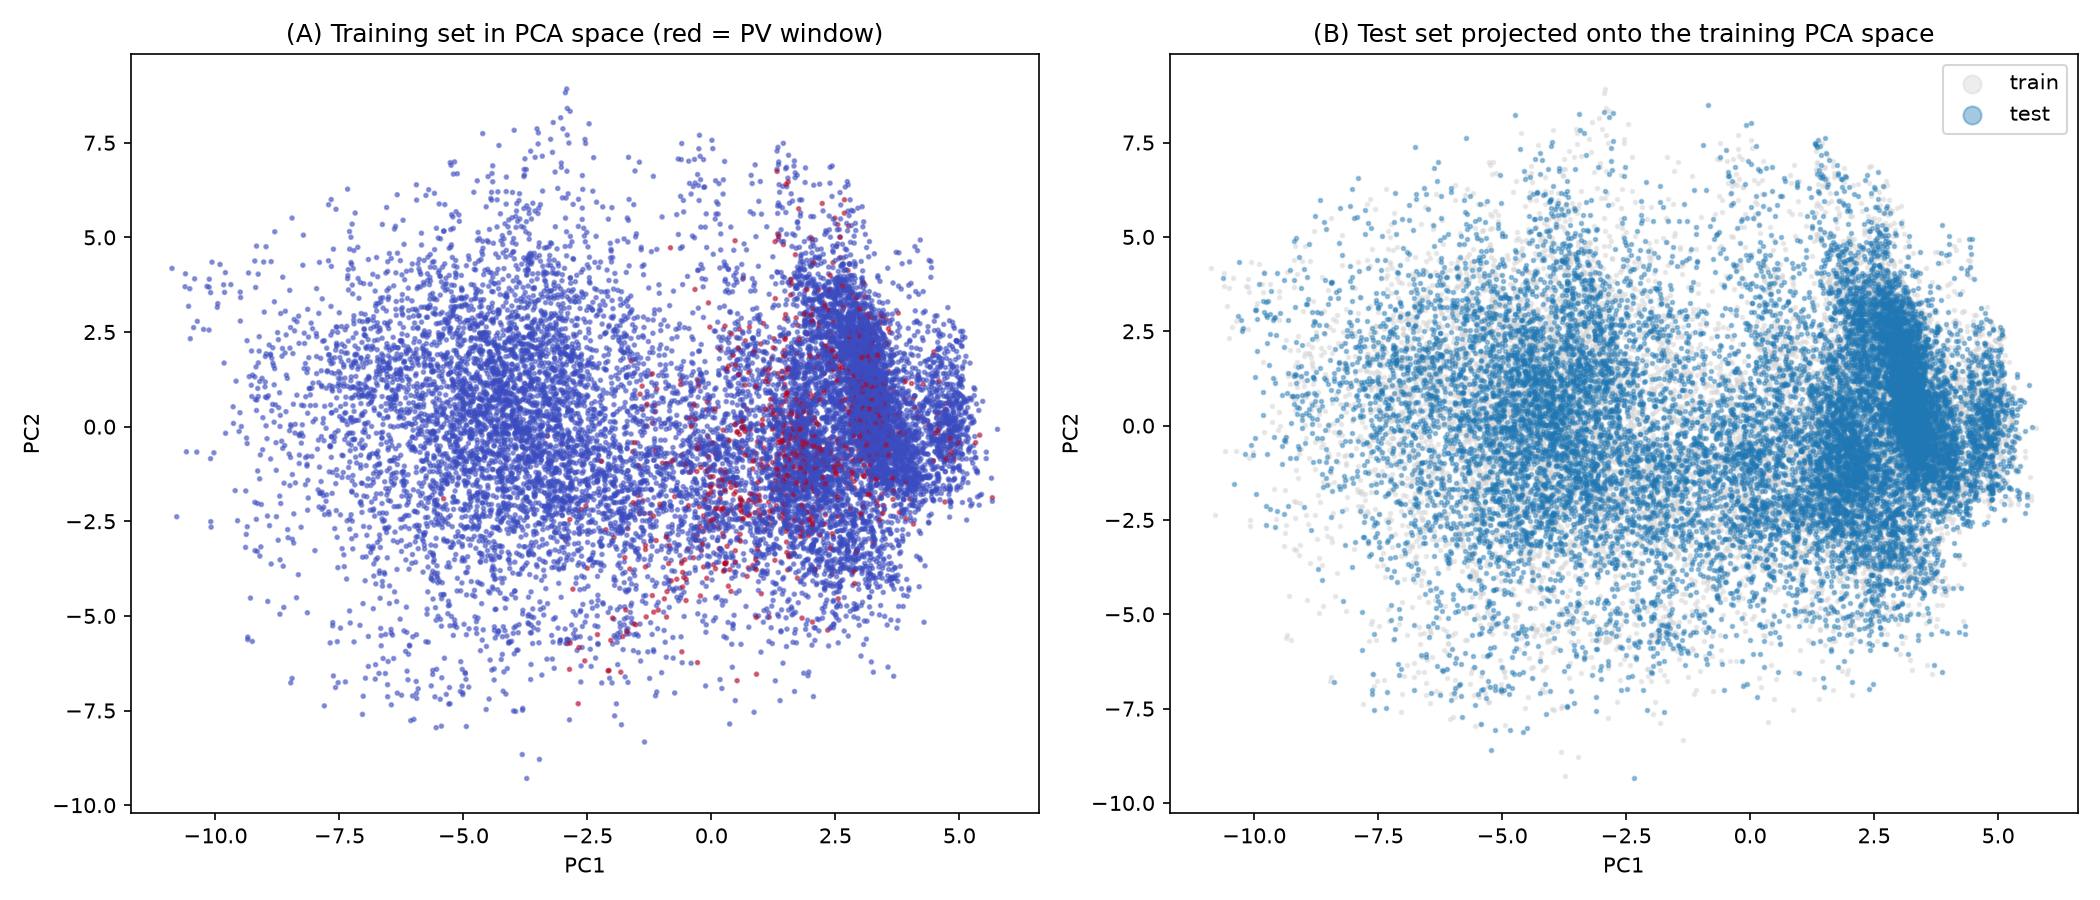

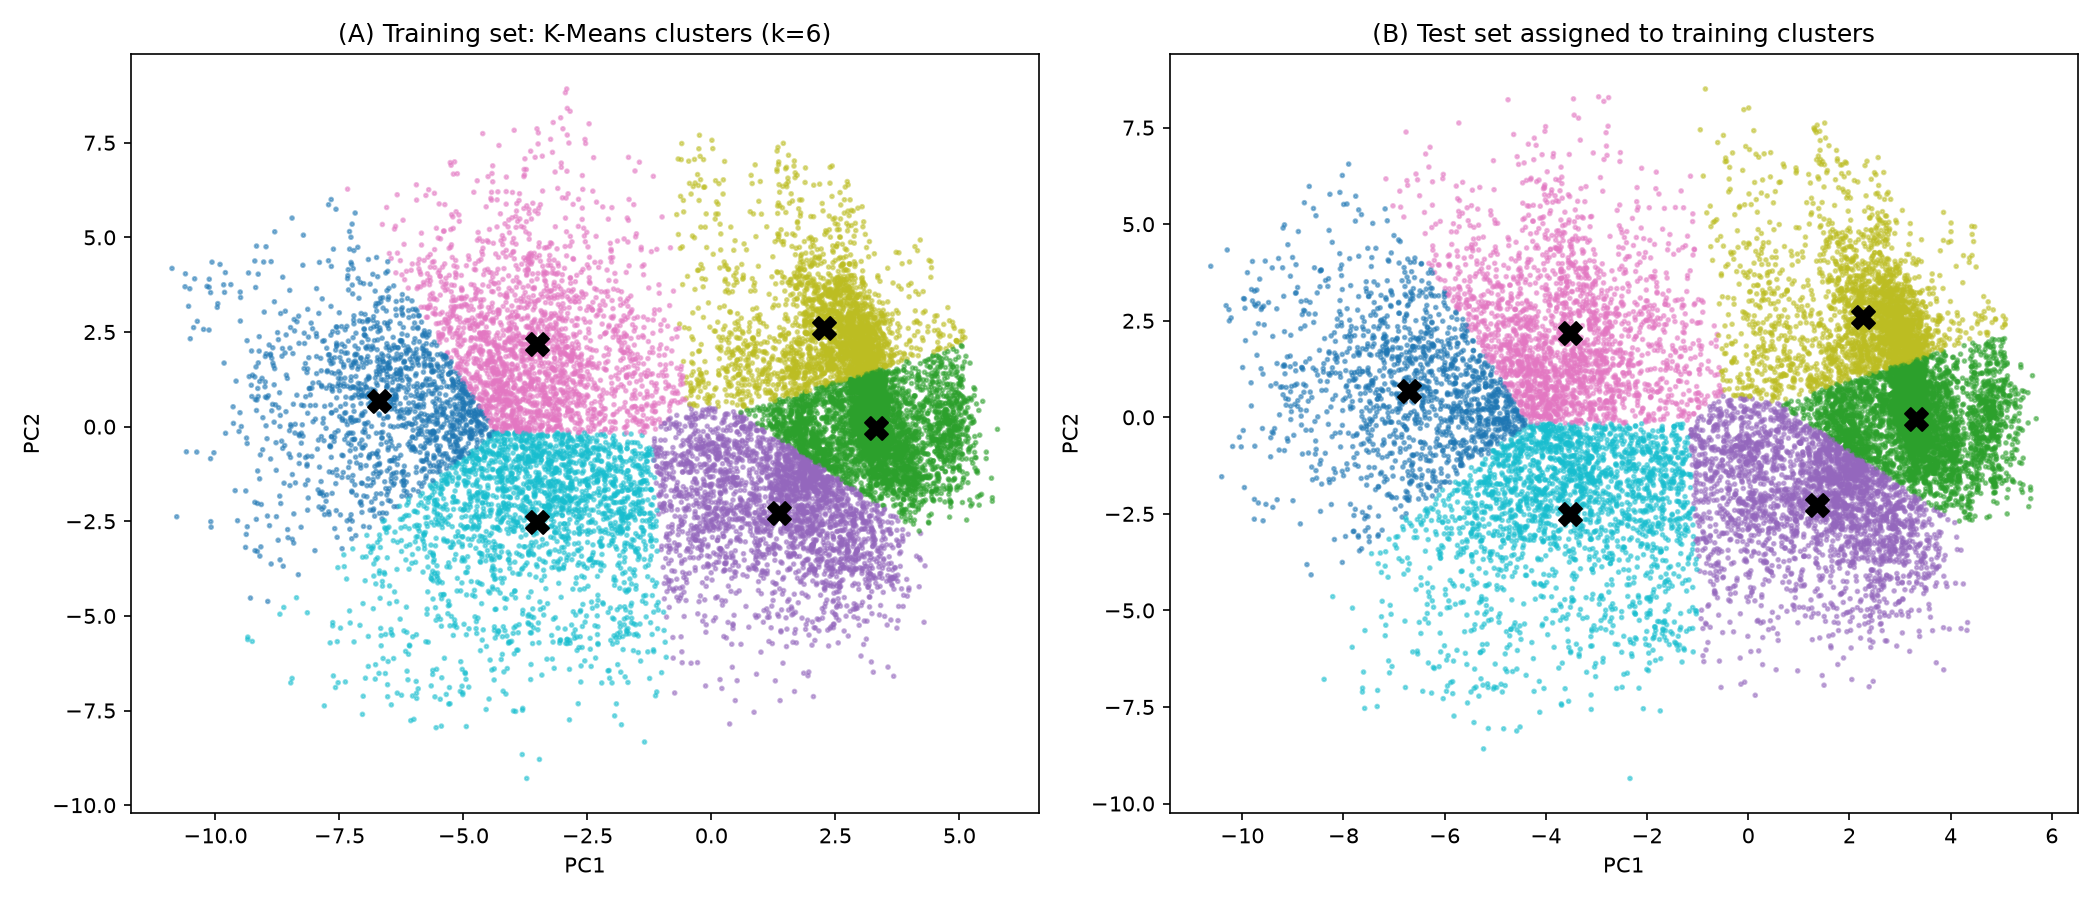

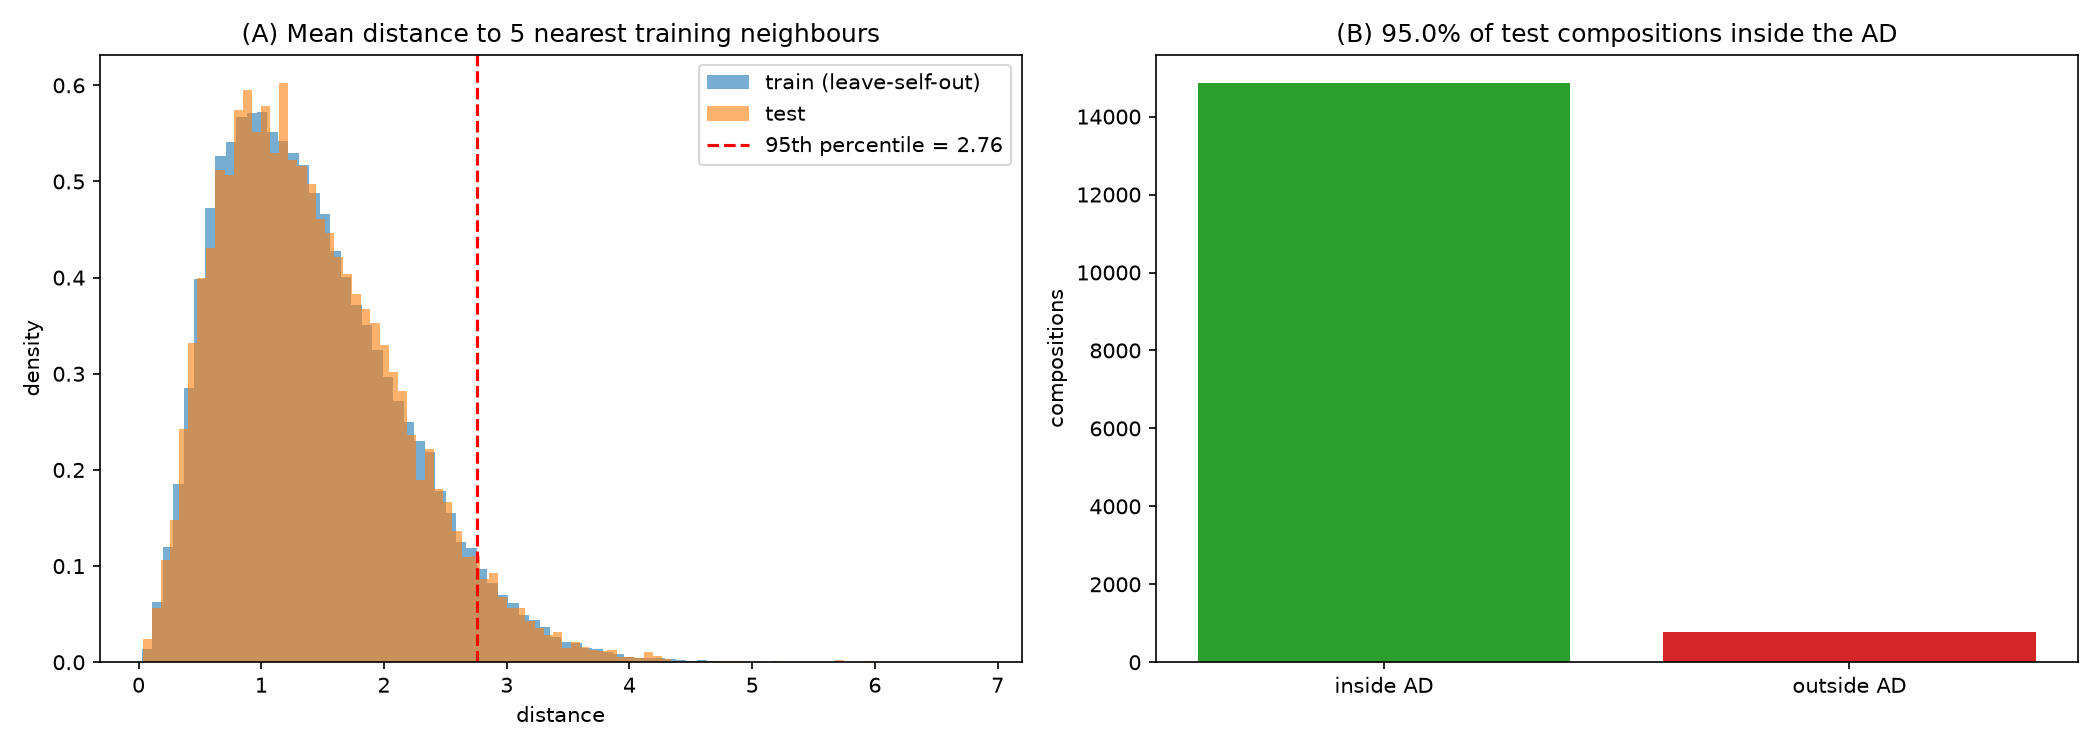

{'pca_variance_2pc': 0.35628312826156616,
 'pc1': 0.2518705427646637,
 'pc2': 0.10441259294748306,
 'kmeans_k': 6,
 'distance_threshold_95pct': 2.7591859102249146,
 'n_test': 15633,
 'n_inside': 14851,
 'n_outside': 782,
 'fraction_inside': 0.949977611462931,
 'metrics_inside': {'Model': 'inside AD',
  'Accuracy': 0.9393980203353309,
  'Precision': 0.6722972972972973,
  'Recall': 0.19860279441117765,
  'F1-Score': 0.3066255778120185,
  'ROC-AUC': 0.9017503299416043,
  'PR-AUC': 0.45818290930489575,
  'Composite_Score': 0.6041879538768113},
 'metrics_outside': {'Model': 'outside AD',
  'Accuracy': 0.9501278772378516,
  'Precision': 0.5,
  'Recall': 0.10256410256410256,
  'F1-Score': 0.1702127659574468,
  'ROC-AUC': 0.93408565413949,
  'PR-AUC': 0.39164244840395585,
  'Composite_Score': 0.5521492100484684}}

In [6]:
# 4. Applicability domain
for f in ('band_gap_ad_pca.png', 'band_gap_ad_kmeans.png', 'band_gap_ad_distance.png'):
    display(Image(str(OUT / f)))
{k: v for k, v in S['applicability_domain'].items() if k != 'cluster_share'}

In [7]:
# 5. Use the saved predictor
import joblib
from run_ssl_experiments import Preprocessor
import __main__
__main__.Preprocessor = Preprocessor
from featurize import featurize_formulas
pkg = joblib.load(ROOT / 'app/models/band_gap_model.pkl')
prep = joblib.load(ROOT / 'app/models/band_gap_scaler.pkl')
for f in ['CdTe', 'GaAs', 'Si', 'CsPbI3', 'Cu2ZnSnS4', 'Al2O3', 'Fe']:
    X = prep.transform(featurize_formulas(pd.Series([f]))[0])[:, pkg['selected_idx']]
    p = pkg['model'].predict_proba(X)[0, 1]
    d = pkg['nn'].kneighbors(X, n_neighbors=5)[0].mean()
    print(f"{f:<10} P(PV window)={p:.3f}  inside AD={d <= pkg['ad_threshold']}")

CdTe       P(PV window)=0.037  inside AD=True
GaAs       P(PV window)=0.023  inside AD=True


Si         P(PV window)=0.610  inside AD=False
CsPbI3     P(PV window)=0.783  inside AD=True


Cu2ZnSnS4  P(PV window)=0.003  inside AD=True
Al2O3      P(PV window)=0.003  inside AD=True


Fe         P(PV window)=0.000  inside AD=True
